# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [26]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [27]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Q1. What is CLIP?
CLIP stands for Contrastive Language–Image Pre-training. It is a model developed by OpenAI that learns relationships between images and textual descriptions. It represents images and texts numerically in a shared space, allowing their similarity to be measured. CLIP can be used for image–text comparison, zero-shot image classification, and text-to-image retrieval.

Q2. What are its two main components?
CLIP has two main components:

An image encoder, which converts an image into a numerical representation of its visual content.

A text encoder, which converts a textual description into a numerical representation.

These representations are projected into a shared space so that they can be compared.

Q3. What is the role of CLIPProcessor?
CLIPProcessor prepares images and texts for the model. It processes images through operations such as resizing and normalization, and tokenizes text into numerical identifiers. In our implementation, it returns PyTorch tensors that can be passed to CLIPModel.

It prepares the inputs but does not calculate their similarity itself.

Q4. What is the role of CLIPModel?
CLIPModel processes the prepared inputs, produces image and text representations, and calculates image–text similarity scores.

In our code, outputs.logits_per_image contains the scores comparing the image with the candidate descriptions. We then apply softmax() to obtain relative probabilities over those descriptions.

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (415, 350)
Image mode: RGB


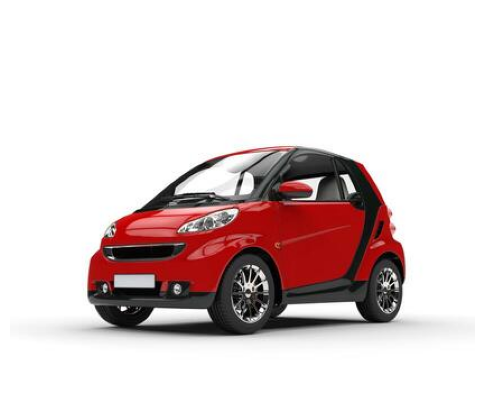

In [28]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "voiture.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

Q5. What is the size of the image?

The image voiture.jpg has a width of 415 pixels and a height of 350 pixels. Pillow displays image dimensions in the order (width, height).

Q6. What type of data is stored in the PIL image object?

The PIL image object stores the image’s pixel data and information such as its dimensions and color mode. After conversion to RGB, each pixel has three color values: red, green, and blue.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [29]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.0003
a photo of a dog                   : 0.0012
a photo of a car                   : 0.9947
a photo of a horse                 : 0.0005
a photo of a person                : 0.0033


Q7. Which description has the highest probability?

The description "a photo of a car" has the highest probability: 0.9947, or approximately 99.47%, among the five candidate descriptions.

Q8. Is it compatible with the actual image?

Yes. The image shows a car, so the highest-ranked description correctly matches its main content.

Q9. Why can CLIP compare an image with a sentence?

CLIP encodes images and sentences into numerical representations in a shared embedding space. This allows the model to measure the similarity between visual content and textual descriptions.

Q10. What does softmax() do?

softmax() converts the similarity scores into values between 0 and 1 that sum to 1 before rounding. In this experiment, it produces a probability distribution over the five candidate descriptions.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [30]:
# STUDENT TASK
def classify_image(image, classes):
    # TODO: implement this function
    pass

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# Uncomment after implementing the function:
# prediction, probability = classify_image(image, classes)
# print("Prediction:", prediction)
# print("Probability:", probability)

In [31]:
def classify_image(image, classes):
    texts = [f"a photo of a {category}" for category in classes]

    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = outputs.logits_per_image.softmax(dim=1)[0]
    best_index = probabilities.argmax().item()

    prediction = classes[best_index]
    probability = probabilities[best_index].item()

    return prediction, probability


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)
print(f"Probability (%): {probability * 100:.2f}%")

Prediction: car
Probability: 0.9976475834846497
Probability (%): 99.76%


Q11. What is zero-shot classification?

Zero-shot classification assigns an image to a category without additional training on labeled examples for the specific classification task. A pretrained model compares the image with textual descriptions of the candidate categories.

Q12. Why is it not necessary to train a new classifier?

CLIP has already learned relationships between images and texts during pretraining. We can therefore describe the desired categories in text, compare them with the image, and select the best match without training a new task-specific classifier.

Q13. What happens if the correct class is not included in the candidate classes?

Our function always selects one of the provided classes. If the correct class is missing, it cannot return the correct label and may select an incorrect class with a high relative probability.

The function has no explicit “none of the above” option.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [32]:
# STUDENT TASK
dataset = [
    # ("cat1.jpg", "cat"),
    # ("cat2.jpg", "cat"),
    # ("dog1.jpg", "dog"),
    # ...
]

# Implement the evaluation after preparing your images.

In [ ]:

from pathlib import Path

dataset = [
    ("chat1.jpg", "cat"),
    ("chat2.jpg", "cat"),
    ("chien1.jpg", "dog"),
    ("chien2.jpg", "dog"),
    ("voiture.jpg", "car"),
    ("voiture2.jpg", "car"),
    ("avion1.jpg", "airplane"),
    ("avion2.jpg", "airplane"),
    ("oiseau1.jpg", "bird"),
    ("oiseau2.jpg", "bird"),
]

missing_files = [
    filename
    for filename, actual_class in dataset
    if not Path(filename).is_file()
]

if missing_files:
    print("Ajoute les fichiers suivants ou corrige leurs noms :")
    for filename in missing_files:
        print("-", filename)

else:
    results = []

    for filename, actual_class in dataset:
        with Image.open(filename) as source:
            test_image = source.convert("RGB")

        prediction, probability = classify_image(test_image, classes)

        results.append({
            "Image": filename,
            "Vraie catégorie": actual_class,
            "Prédiction": prediction,
            "Probabilité (%)": probability * 100,
            "Correct": prediction == actual_class
        })

    df_results = pd.DataFrame(results)
    display(df_results)

    correct_count = int(df_results["Correct"].sum())
    total_count = len(df_results)
    accuracy = correct_count / total_count

    print(f"Bonnes réponses : {correct_count}/{total_count}")
    print(f"Accuracy : {accuracy * 100:.2f}%")

,Image,Vraie catégorie,Prédiction,Probabilité (%),Correct
0,chat1.jpg,cat,cat,99.583697,True
1,chat2.jpg,cat,cat,99.553597,True
2,chien1.jpg,dog,dog,99.788058,True
3,chien2.jpg,dog,dog,97.492230,True
4,voiture.jpg,car,car,99.764758,True
5,voiture2.jpg,car,car,99.616170,True
6,avion1.jpg,airplane,airplane,98.079592,True
7,avion2.jpg,airplane,airplane,99.285758,True
8,oiseau1.jpg,bird,bird,99.957103,True
9,oiseau2.jpg,bird,bird,99.825257,True


Bonnes réponses : 10/10
Accuracy : 100.00%


Q14. What is the obtained accuracy?
The obtained classification accuracy is 100%. All 10 images were correctly classified.

Accuracy=(10/10)×100=100%

The test set contained two cats, two dogs, two cars, two airplanes, and two birds.

Q15. Which images are incorrectly classified?

None of the 10 images were incorrectly classified. All entries in the Correct column were True.

Q16. Give at least two possible reasons for the errors.

Although no errors occurred in this test, possible causes of classification errors include:
Blurry images, partially hidden objects, or visually ambiguous scenes.
Candidate descriptions that are poorly formulated or do not match the image well.
Several prominent objects in the same image.
The absence of the correct category from the candidate list.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [33]:
# STUDENT TASK
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Calculate and compare the scores for all prompts.

In [34]:

with Image.open("chat1.jpg") as source:
    cat_image = source.convert("RGB")

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=cat_image,
    return_tensors="pt",
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].cpu()
probabilities = scores.softmax(dim=0)

df_prompts = pd.DataFrame({
    "Prompt": prompts,
    "Score CLIP": scores.tolist(),
    "Probabilité (%)": (probabilities * 100).tolist()
})

display(df_prompts)

best_index = scores.argmax().item()
print("Prompt avec le score le plus élevé :", prompts[best_index])

,Prompt,Score CLIP,Probabilité (%)
0,a cat,26.418564,4.241352
1,a photo of a cat,26.971684,7.374305
2,a photograph showing a cat,27.415615,11.495242
3,an image containing a cat,27.618849,14.085796
4,a domestic animal called a cat,29.113689,62.803299


Prompt avec le score le plus élevé : a domestic animal called a cat


Q17. Are the scores identical?

No. Different formulations produced different scores, even though all five prompts referred to a cat.

Q18. Which prompt gives the highest score?

The prompt "a domestic animal called a cat" gives the highest score: 29.113689. Its relative probability among the five prompts is approximately 62.80%.

Q19. What does this demonstrate about prompt formulation?

The experiment demonstrates that wording influences CLIP’s image–text similarity scores. Testing different formulations can help identify a better match for a particular image or dataset.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [35]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.

IMAGE_DIR = "images"
QUERY = "a person playing football"

Number of images found: 20


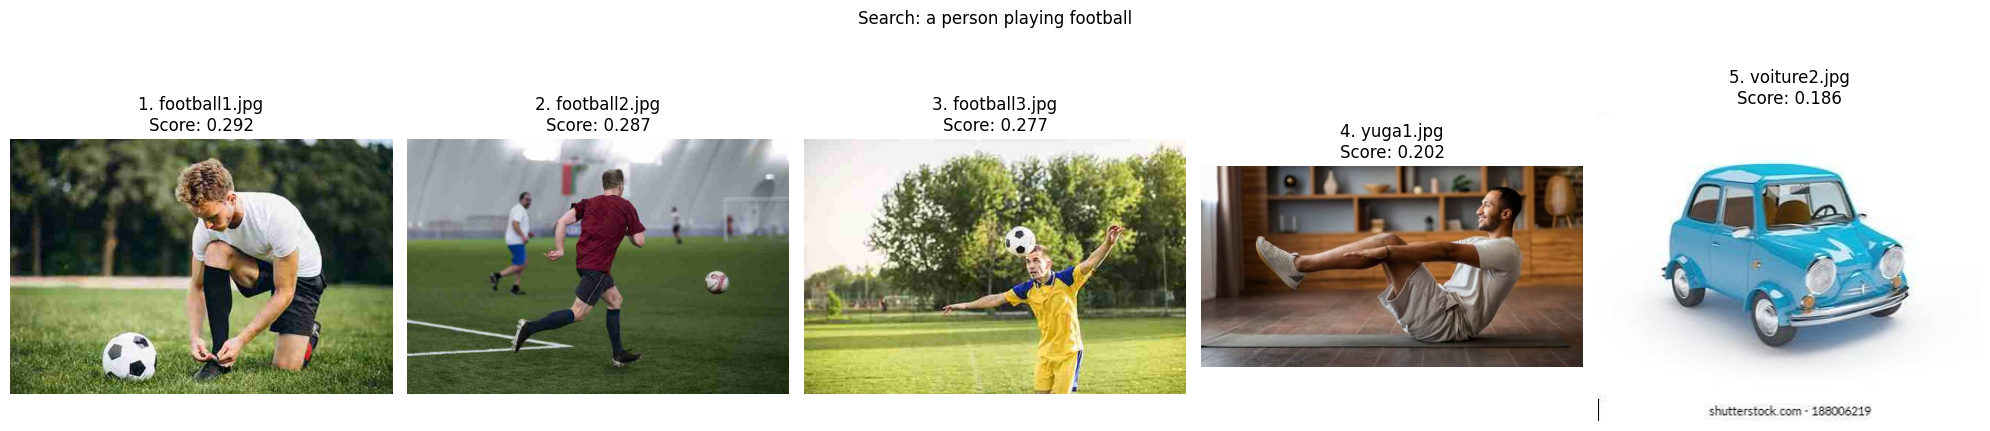

,Rank,Image,Cosine similarity
0,1,football1.jpg,0.291813
1,2,football2.jpg,0.286512
2,3,football3.jpg,0.277089
3,4,yuga1.jpg,0.202167
4,5,voiture2.jpg,0.186029


In [36]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_DIR = Path("/content/")
QUERY = "a person playing football"

image_paths = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
) if IMAGE_DIR.is_dir() else []

print("Number of images found:", len(image_paths))

if len(image_paths) < 20:
    print("Please add at least 20 images to /content/images.")

else:
    model.eval()
    image_embeddings = []
    valid_paths = []
    query_embedding = None

    for path in image_paths:
        try:
            with Image.open(path) as source:
                current_image = source.convert("RGB")
        except OSError as error:
            print("Cannot open:", path.name, "-", error)
            continue

        inputs = processor(
            text=[QUERY],
            images=current_image,
            return_tensors="pt",
            padding=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)

        image_vector = outputs.image_embeds
        image_vector = image_vector / image_vector.norm(
            dim=-1, keepdim=True
        )

        image_embeddings.append(image_vector.cpu())
        valid_paths.append(path)

        if query_embedding is None:
            query_embedding = outputs.text_embeds
            query_embedding = query_embedding / query_embedding.norm(
                dim=-1, keepdim=True
            )
            query_embedding = query_embedding.cpu()

    if len(valid_paths) < 20:
        print("At least 20 readable images are needed.")
        print("Readable images:", len(valid_paths))

    else:
        image_embeddings = torch.cat(image_embeddings, dim=0)
        similarities = (image_embeddings @ query_embedding.T).squeeze(1)
        top_scores, top_indices = similarities.topk(5)

        results = []
        fig, axes = plt.subplots(1, 5, figsize=(20, 5))

        for rank, (score, index) in enumerate(
            zip(top_scores, top_indices), start=1
        ):
            path = valid_paths[index.item()]

            results.append({
                "Rank": rank,
                "Image": path.name,
                "Cosine similarity": score.item()
            })

            with Image.open(path) as source:
                axes[rank - 1].imshow(source.convert("RGB"))

            axes[rank - 1].set_title(
                f"{rank}. {path.name}\nScore: {score.item():.3f}"
            )
            axes[rank - 1].axis("off")

        plt.suptitle(f"Search: {QUERY}")
        plt.tight_layout()
        plt.show()

        df_retrieval = pd.DataFrame(results)
        display(df_retrieval)

Q20. What is the most similar image?
The most similar image to "a person playing football" is football1.jpg, with a cosine similarity score of 0.297676.
| Rank | Image         | Cosine similarity |
| ---- | ------------- | ----------------- |
| 1    | football1.jpg | 0.291813          |
| 2    | football2.jpg | 0.286512          |
| 3    | football3.jpg | 0.277089          |
| 4    | yuga1.jpg     | 0.202167          |
| 5    | voiture2.jpg	 |0.186029           |

 Q21. Is it semantically relevant?
Yes, it is relevant to the football theme because it shows a person next to a football on grass. However, the person is tying a shoe rather than actively playing football at that moment.
The result matches the theme better than the exact action described in the query.

Q22. Why does this method not require image labels?

The method compares the image embeddings with the embedding of the text query. Therefore, manually assigned category labels are not required for the images in the retrieval database.

The filenames are used to identify and display the results, not to calculate their similarity.

Q23. Give one real-world application of semantic image retrieval.

One application is searching a photo library using natural-language descriptions, such as finding images of “a person playing football” without manually adding keywords to every photo.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

Q24. What is the role of the vision encoder?

The vision encoder converts the image into numerical visual features that represent its content. These features are then passed to the projection layer.

Q25. Why is a projection layer required?

The vision encoder and language model use different representation spaces. The projection layer transforms the visual features into representations compatible with the language model’s input space.

It acts as a bridge between the visual and language components.

Q26. What is the role of the language model?

The language model uses the projected visual information together with the user’s question or instruction to generate a textual response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [37]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )
!pip install -q accelerate bitsandbytes

In [1]:
import sys
import torch
import transformers
import bitsandbytes as bnb
import accelerate

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("Transformers :", transformers.__version__)
print("bitsandbytes :", bnb.__version__)
print("Accelerate :", accelerate.__version__)
print("CUDA PyTorch :", torch.version.cuda)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Python : 3.13.15
PyTorch : 2.11.0+cu130
Transformers : 5.18.0
bitsandbytes : 0.50.2
Accelerate : 1.15.0
CUDA PyTorch : 13.0
GPU disponible : True
GPU : Tesla T4


In [38]:
%pip install --upgrade "bitsandbytes>=0.46.1" accelerate

In [2]:
import gc
import torch
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU non disponible. Sélectionne un GPU dans Colab."
    )

# Déplacer CLIP vers le CPU pour libérer de la mémoire GPU.
if "model" in globals():
    model = model.to("cpu")

gc.collect()
torch.cuda.empty_cache()

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

llava.eval()

print("LLaVA chargé avec succès.")
print("GPU :", torch.cuda.get_device_name(0))

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA chargé avec succès.
GPU : Tesla T4


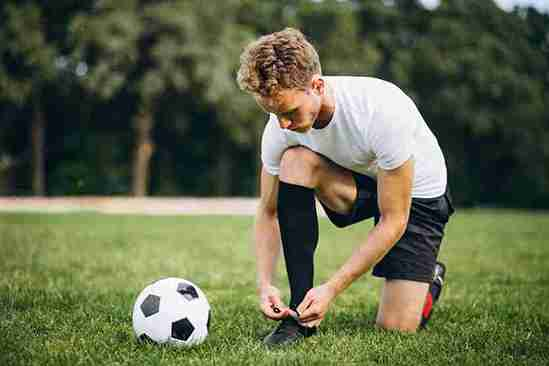


Question 1/4 : What is happening in this image?
Réponse : In the image, a young man is bending over to tie his shoe while standing on a grassy field. The scene takes place in a park, and there is a soccer ball nearby.

Question 2/4 : How many people are visible?
Réponse : There is only one person visible in the image.

Question 3/4 : What objects can you identify?
Réponse : In the image, you can identify a soccer ball and a pair of black socks. The man is bending over to tie his socks, which are placed next to the soccer ball.

Question 4/4 : Describe the image in detail.
Réponse : The image features a young man wearing a white shirt and black shorts, bending over to tie his shoe. He is standing next to a soccer ball, which is located towards the left side of the scene. The man appears to be focused on his task, possibly preparing for a soccer game or practice.


,Image,Question,LLaVA Answer
0,football1.jpg,What is happening in this image?,"In the image, a young man is bending over to t..."
1,football1.jpg,How many people are visible?,There is only one person visible in the image.
2,football1.jpg,What objects can you identify?,"In the image, you can identify a soccer ball a..."
3,football1.jpg,Describe the image in detail.,The image features a young man wearing a white...


In [5]:
from pathlib import Path
from PIL import Image
import pandas as pd
import torch

IMAGE_PATH_LLAVA = "/content/football1.jpg"

if not Path(IMAGE_PATH_LLAVA).is_file():
    raise FileNotFoundError(
        f"Image introuvable : {IMAGE_PATH_LLAVA}"
    )

with Image.open(IMAGE_PATH_LLAVA) as source:
    llava_image = source.convert("RGB")

display(llava_image)


def ask_llava(image, question):
    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to(llava.device, torch.float16)

    with torch.inference_mode():
        output_ids = llava.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[1]
    answer_ids = output_ids[0, input_length:]

    return processor_llava.decode(
        answer_ids,
        skip_special_tokens=True
    ).strip()


questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

llava_results = []

for number, question in enumerate(questions, start=1):
    print(f"\nQuestion {number}/4 : {question}", flush=True)

    answer = ask_llava(llava_image, question)

    print("Réponse :", answer, flush=True)

    llava_results.append({
        "Image": Path(IMAGE_PATH_LLAVA).name,
        "Question": question,
        "LLaVA Answer": answer
    })

df_llava_ex10 = pd.DataFrame(llava_results)
display(df_llava_ex10)

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?


IMAGE : football1.jpg


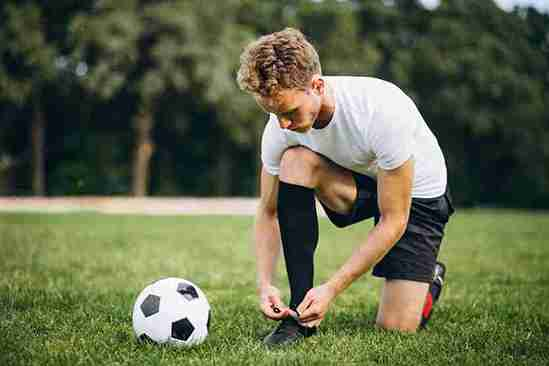


Question 1/25 : How many people are visible?
Réponse : There is only one person visible in the image.

Question 2/25 : What are the main objects or animals visible?
Réponse : The main objects or animals visible in the image are a soccer ball and a man.

Question 3/25 : Is the scene indoors or outdoors?
Réponse : The scene is outdoors, as the man is wearing a white shirt and black shorts while tying his shoe on a grassy field.

Question 4/25 : What is the visible person or animal doing?
Réponse : The visible person, a young man, is bending over and tying his shoe.

Question 5/25 : Describe the position of the main person or animal.
Réponse : The main person, a young man, is kneeling down on the grass.

IMAGE : football2.jpg


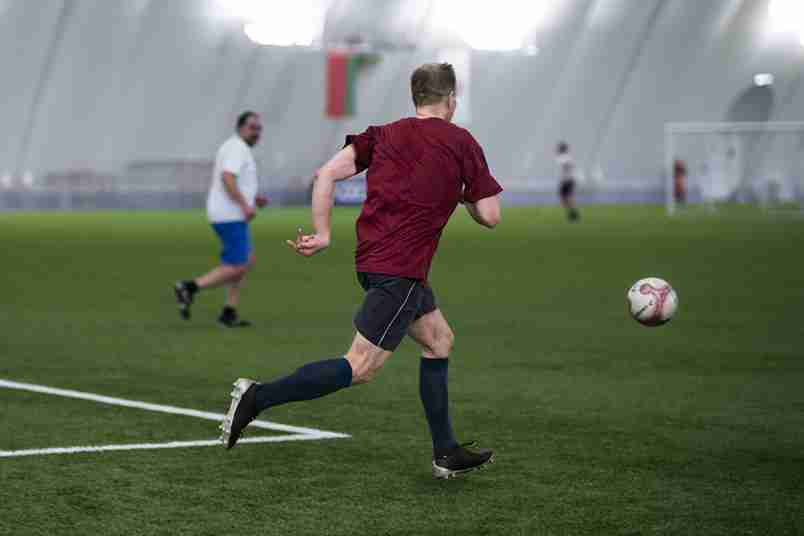


Question 6/25 : How many people are visible?
Réponse : There are three people visible in the image.

Question 7/25 : What are the main objects or animals visible?
Réponse : The main objects or animals visible in the image are a soccer ball and a man running on a field.

Question 8/25 : Is the scene indoors or outdoors?
Réponse : The scene is outdoors, as the men are playing soccer on a field.

Question 9/25 : What is the visible person or animal doing?
Réponse : The visible person or animal is running on a field, possibly kicking a soccer ball.

Question 10/25 : Describe the position of the main person or animal.
Réponse : The main person in the image is a soccer player who is running towards the soccer ball, likely preparing to kick it or make a play.

IMAGE : football3.jpg


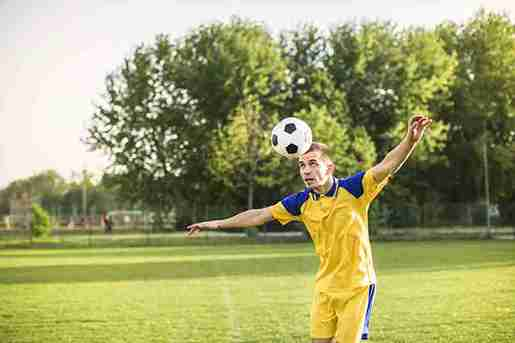


Question 11/25 : How many people are visible?
Réponse : There is only one person visible in the image.

Question 12/25 : What are the main objects or animals visible?
Réponse : The main objects visible in the image are a soccer ball and a man.

Question 13/25 : Is the scene indoors or outdoors?
Réponse : The scene is outdoors, as the man is playing soccer on a field.

Question 14/25 : What is the visible person or animal doing?
Réponse : The visible person, a young man, is playing with a soccer ball in a park. He is either kicking the ball or preparing to kick it, while the soccer ball is in the air.

Question 15/25 : Describe the position of the main person or animal.
Réponse : The main person, a young man, is in the middle of a soccer field, with his arms outstretched, as he attempts to catch a soccer ball.

IMAGE : chien2.jpg


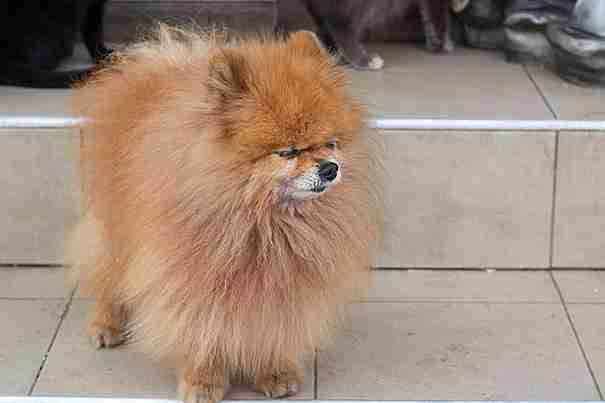


Question 16/25 : How many people are visible?
Réponse : There are no people visible in the image.

Question 17/25 : What are the main objects or animals visible?
Réponse : The main objects or animals visible in the image are a dog and a cat.

Question 18/25 : Is the scene indoors or outdoors?
Réponse : The scene is outdoors, as the dog is standing on a sidewalk.

Question 19/25 : What is the visible person or animal doing?
Réponse : The visible person or animal is a dog, which is standing on a step or a staircase.

Question 20/25 : Describe the position of the main person or animal.
Réponse : The main person or animal, which is a large, fluffy dog, is standing on a step or a stairway.

IMAGE : yuga1.jpg


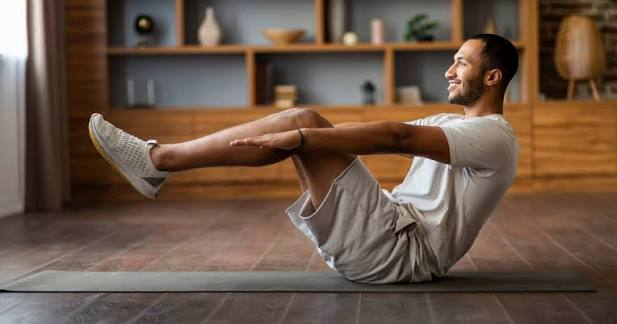


Question 21/25 : How many people are visible?
Réponse : There is only one person visible in the image.

Question 22/25 : What are the main objects or animals visible?
Réponse : The main objects visible in the image are a man and a dog.

Question 23/25 : Is the scene indoors or outdoors?
Réponse : The scene is indoors, as the man is doing yoga in a living room.

Question 24/25 : What is the visible person or animal doing?
Réponse : The visible person or animal is a man who is doing a yoga pose on the floor.

Question 25/25 : Describe the position of the main person or animal.
Réponse : The main person is lying on the floor, possibly on a yoga mat, and is in a relaxed position.


,ID,Image,Question,LLaVA Answer,Human Evaluation
0,1,football1.jpg,How many people are visible?,There is only one person visible in the image.,À vérifier
1,2,football1.jpg,What are the main objects or animals visible?,The main objects or animals visible in the image are a soccer ball and a man.,À vérifier
2,3,football1.jpg,Is the scene indoors or outdoors?,"The scene is outdoors, as the man is wearing a white shirt and black shorts while tying his shoe on a grassy field.",À vérifier
3,4,football1.jpg,What is the visible person or animal doing?,"The visible person, a young man, is bending over and tying his shoe.",À vérifier
4,5,football1.jpg,Describe the position of the main person or animal.,"The main person, a young man, is kneeling down on the grass.",À vérifier
5,6,football2.jpg,How many people are visible?,There are three people visible in the image.,À vérifier
6,7,football2.jpg,What are the main objects or animals visible?,The main objects or animals visible in the image are a soccer ball and a man running on a field.,À vérifier
7,8,football2.jpg,Is the scene indoors or outdoors?,"The scene is outdoors, as the men are playing soccer on a field.",À vérifier
8,9,football2.jpg,What is the visible person or animal doing?,"The visible person or animal is running on a field, possibly kicking a soccer ball.",À vérifier
9,10,football2.jpg,Describe the position of the main person or animal.,"The main person in the image is a soccer player who is running towards the soccer ball, likely preparing to kick it or make a play.",À vérifier


Nombre de réponses enregistrées : 25


In [6]:
from pathlib import Path
from PIL import Image
import pandas as pd

image_folder = Path("/content/")

vqa_images = [
    "football1.jpg",
    "football2.jpg",
    "football3.jpg",
    "chien2.jpg",
    "yuga1.jpg"
]

vqa_questions = [
    "How many people are visible?",
    "What are the main objects or animals visible?",
    "Is the scene indoors or outdoors?",
    "What is the visible person or animal doing?",
    "Describe the position of the main person or animal."
]

missing_files = [
    name for name in vqa_images
    if not (image_folder / name).is_file()
]

if missing_files:
    print("Fichiers introuvables :")
    for name in missing_files:
        print("-", name)

else:
    vqa_results = []

    for image_name in vqa_images:
        with Image.open(image_folder / image_name) as source:
            current_image = source.convert("RGB")

        print(f"\nIMAGE : {image_name}", flush=True)
        display(current_image)

        for question in vqa_questions:
            number = len(vqa_results) + 1
            print(f"\nQuestion {number}/25 : {question}", flush=True)

            answer = ask_llava(current_image, question)
            print("Réponse :", answer, flush=True)

            vqa_results.append({
                "ID": number,
                "Image": image_name,
                "Question": question,
                "LLaVA Answer": answer,
                "Human Evaluation": "À vérifier"
            })

    df_vqa = pd.DataFrame(vqa_results)

    pd.set_option("display.max_colwidth", None)
    display(df_vqa)

    print("Nombre de réponses enregistrées :", len(df_vqa))

In [7]:
evaluation_by_id = {
    1: 1, 2: 1, 3: 1, 4: 1, 5: 1,
    6: 1, 7: 1, 8: 0, 9: 1, 10: 1,
    11: 1, 12: 1, 13: 1, 14: 0, 15: 0,
    16: 1, 17: 1, 18: 1, 19: 1, 20: 1,
    21: 1, 22: 0, 23: 1, 24: 1, 25: 0
}

df_vqa["Human Evaluation"] = df_vqa["ID"].map(evaluation_by_id)

if len(df_vqa) != 25 or df_vqa["Human Evaluation"].isna().any():
    raise ValueError("Vérifie que le tableau contient bien les 25 réponses.")

display(df_vqa)

correct_answers = int(df_vqa["Human Evaluation"].sum())
total_questions = len(df_vqa)
vqa_accuracy = correct_answers / total_questions

print(f"Réponses correctes : {correct_answers}/{total_questions}")
print(f"VQA accuracy : {vqa_accuracy * 100:.2f}%")

,ID,Image,Question,LLaVA Answer,Human Evaluation
0,1,football1.jpg,How many people are visible?,There is only one person visible in the image.,1
1,2,football1.jpg,What are the main objects or animals visible?,The main objects or animals visible in the image are a soccer ball and a man.,1
2,3,football1.jpg,Is the scene indoors or outdoors?,"The scene is outdoors, as the man is wearing a white shirt and black shorts while tying his shoe on a grassy field.",1
3,4,football1.jpg,What is the visible person or animal doing?,"The visible person, a young man, is bending over and tying his shoe.",1
4,5,football1.jpg,Describe the position of the main person or animal.,"The main person, a young man, is kneeling down on the grass.",1
5,6,football2.jpg,How many people are visible?,There are three people visible in the image.,1
6,7,football2.jpg,What are the main objects or animals visible?,The main objects or animals visible in the image are a soccer ball and a man running on a field.,1
7,8,football2.jpg,Is the scene indoors or outdoors?,"The scene is outdoors, as the men are playing soccer on a field.",0
8,9,football2.jpg,What is the visible person or animal doing?,"The visible person or animal is running on a field, possibly kicking a soccer ball.",1
9,10,football2.jpg,Describe the position of the main person or animal.,"The main person in the image is a soccer player who is running towards the soccer ball, likely preparing to kick it or make a play.",1


Réponses correctes : 20/25
VQA accuracy : 80.00%


Q27. What is the VQA accuracy?
The VQA accuracy is 80%. Human evaluation judged 20 of the 25 answers correct.

VQA Accuracy = 20/25×100=80%.

We used the following rule:

1: the answer is correct and contains no significant factual error.

0: the answer is incorrect, introduces a significant unsupported detail, or fails to answer the question.
| Image         | Correct answers | Total questions |
| ------------- | --------------- | --------------- |
| football1.jpg | 5               | 5               |
| football2.jpg | 4               | 5               |
| football3.jpg | 3               | 5               |
| chien2.jpg    | 5               | 5               |
| yuga1.jpg     | 3               | 5               |
| Total         | 20              | 25              |


Q28. Which types of questions are difficult for LLaVA?
In our experiment, errors occurred in:
Scene interpretation: the covered football field in football2.jpg was incorrectly described as outdoors.
Action recognition: the person in football3.jpg was described as about to kick the ball, although the ball was near the head.
Posture description: the person in yuga1.jpg was described as lying down in a relaxed position, whereas the torso and legs were raised.

Object identification: LLaVA mentioned a dog that was absent from yuga1.jpg.

All five person-counting answers were correct in this experiment.


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

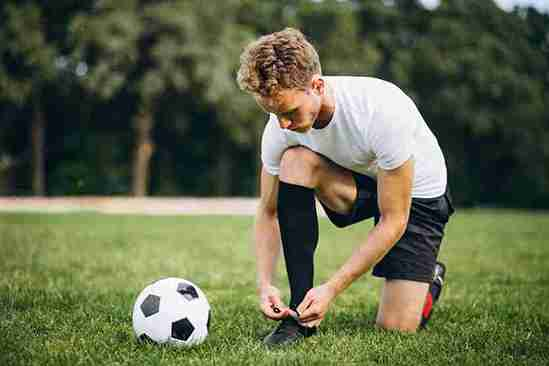


Question 1/3 : Is there a bicycle in this image?
Réponse : No, there is no bicycle in this image. The focus is on a man tying his shoe while standing next to a soccer ball.

Question 2/3 : What color is the bicycle?
Réponse : The bicycle is black.

Question 3/3 : Where is the bicycle located?
Réponse : The bicycle is located in a park.


,Image,Question,LLaVA Answer
0,football1.jpg,Is there a bicycle in this image?,"No, there is no bicycle in this image. The focus is on a man tying his shoe while standing next to a soccer ball."
1,football1.jpg,What color is the bicycle?,The bicycle is black.
2,football1.jpg,Where is the bicycle located?,The bicycle is located in a park.


In [8]:
from PIL import Image
import pandas as pd

with Image.open("/content/football1.jpg") as source:
    hallucination_image = source.convert("RGB")

display(hallucination_image)

questions_hallucination = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

results_hallucination = []

for number, question in enumerate(questions_hallucination, start=1):
    print(f"\nQuestion {number}/3 : {question}", flush=True)

    answer = ask_llava(hallucination_image, question)

    print("Réponse :", answer, flush=True)

    results_hallucination.append({
        "Image": "football1.jpg",
        "Question": question,
        "LLaVA Answer": answer
    })

df_hallucination = pd.DataFrame(results_hallucination)
display(df_hallucination)

Q29. Does the bicycle actually exist?

No. There is no bicycle in football1.jpg. The image shows a person tying a shoe on grass next to a football.

Q30. Did LLaVA invent information?

Yes. LLaVA correctly answered that no bicycle was present in response to the first question. However, it then stated that the bicycle was black and located in a park.

These details were invented because the image contained no bicycle.

Q31. What is a visual hallucination?

A visual hallucination occurs when a model generates information that does not match the image, such as an absent object, an incorrect attribute, or an unsupported action.

In this experiment, the model assigned a color and location to a nonexistent bicycle.

Q32. Why can a multimodal model hallucinate?

A multimodal model may rely too heavily on the wording of a question and on learned language associations instead of grounding its answer in the image.
Questions such as “What color is the bicycle?” assume that a bicycle exists. The model may accept this false premise and produce a plausible-sounding answer instead of rejecting it.
This is a possible explanation; our experiment does not identify the precise internal cause of each response.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [11]:
from transformers import CLIPModel, AutoProcessor

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"

# Load CLIP on the CPU.
model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to("cpu")
processor = AutoProcessor.from_pretrained(CLIP_MODEL_ID)

model.eval()

print("CLIP successfully loaded on CPU.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP successfully loaded on CPU.


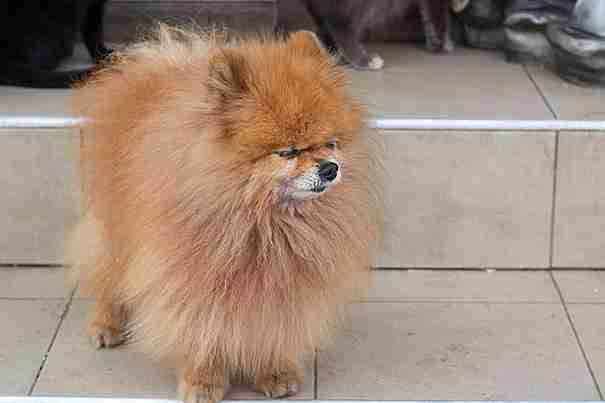

RÉSULTATS CLIP


,Description,Probabilité (%)
0,a photo of a cat,2.209538
1,a photo of a dog,97.581917
2,a photo of a horse,0.208555


Description choisie : a photo of a dog

RÉSULTAT LLaVA
Question : What animal is present in the image? Describe its appearance.
Réponse : A dog is present in the image. It has a fluffy, shaggy appearance, which is typical for breeds with long, thick fur.


In [12]:
from PIL import Image
import torch
import pandas as pd

with Image.open("/content/chien2.jpg") as source:
    comparison_image = source.convert("RGB")

display(comparison_image)

# Partie CLIP : comparer les trois descriptions.
model = model.to("cpu")
model.eval()

comparison_texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

clip_inputs = processor(
    text=comparison_texts,
    images=comparison_image,
    return_tensors="pt",
    padding=True
)
clip_inputs = {k: v.to("cpu") for k, v in clip_inputs.items()}

with torch.inference_mode():
    clip_outputs = model(**clip_inputs)

clip_probabilities = clip_outputs.logits_per_image.softmax(dim=1)[0]
best_index = clip_probabilities.argmax().item()

df_comparison_clip = pd.DataFrame({
    "Description": comparison_texts,
    "Probabilité (%)": (clip_probabilities * 100).tolist()
})

print("RÉSULTATS CLIP")
display(df_comparison_clip)

print("Description choisie :", comparison_texts[best_index])

# Partie LLaVA : répondre sur la même image.
comparison_question = (
    "What animal is present in the image? Describe its appearance."
)

comparison_answer = ask_llava(
    comparison_image,
    comparison_question
)

print("\nRÉSULTAT LLaVA")
print("Question :", comparison_question)
print("Réponse :", comparison_answer)

LLaVA identified the animal as a dog and described its fur as fluffy, shaggy, long, and thick. The response provides an open-ended description rather than selecting from predefined labels. The accuracy of these visual details must be checked against the image. The answer does not describe the dog's colors or identify a specific breed.

comparison table

| Property                 | CLIP                                                                             | LLaVA                                                                            |
| ------------------------ | -------------------------------------------------------------------------------- | -------------------------------------------------------------------------------- |
| Input                    | Images and/or text; classification compares an image with candidate descriptions | An image and a textual question or instruction                                   |
| Main output              | Embeddings and image–text similarity scores                                      | Generated text                                                                   |
| Zero-shot classification | Selects the best-matching candidate category                                     | Can generate a category label when instructed                                    |
| Image retrieval          | Directly supports embedding-based image ranking                                  | Not a built-in retrieval system; additional ranking or retrieval logic is needed |
| Text generation          | Does not generate free-form text by itself                                       | Generates descriptions and answers                                               |
| VQA                      | Can rank predefined candidate answers, but does not generate open-ended answers  | Generates answers to visual questions                                            |
| Open-ended response      | No                                                                               | Yes                                                                              |

Q33. Which model is better suited to image classification?

CLIP is more directly suited to classification among candidate categories because it compares their descriptions with the image and ranks them by similarity.
This concerns suitability for the task, not a guarantee that CLIP is always more accurate than LLaVA.

Q34. Which model is better for image description?

LLaVA is better suited to image description because it generates natural-language descriptions. CLIP alone produces representations and similarity scores rather than free-text descriptions.

Q35. Which model is better for visual question answering?

LLaVA is better suited to visual question answering because it accepts an image and a question and generates a response. The response still requires verification.

Q36. Explain the fundamental difference between CLIP and LLaVA.

CLIP is primarily a representation and comparison model: it maps images and texts into a shared numerical space to measure their similarity.
LLaVA is a generative multimodal model: it connects visual information to a language model to generate responses to questions or instructions.



# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [14]:
from pathlib import Path
from PIL import Image
import pandas as pd

assistant_history = []


def multimodal_assistant(image_path, question):
    image_path = Path(image_path)
    question = question.strip()

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image introuvable : {image_path}"
        )

    if not question:
        raise ValueError("Écris une question avant de continuer.")

    with Image.open(image_path) as source:
        assistant_image = source.convert("RGB")

    print("IMAGE :", image_path.name)
    display(assistant_image)

    print("QUESTION :", question, flush=True)

    answer = ask_llava(assistant_image, question)

    print("\nRÉPONSE :", answer)
    print("\nAttention : vérifie la réponse avec l’image.")

    assistant_history.append({
        "Image": str(image_path),
        "Question": question,
        "Answer": answer
    })

    return answer


print("Assistant prêt. Lance la cellule suivante pour poser une question.")

Assistant prêt. Lance la cellule suivante pour poser une question.


Chemin de l’image (Entrée pour /content/chien2.jpg) : /content/chien2.jpg
Ta question : What color is the dog?
IMAGE : chien2.jpg


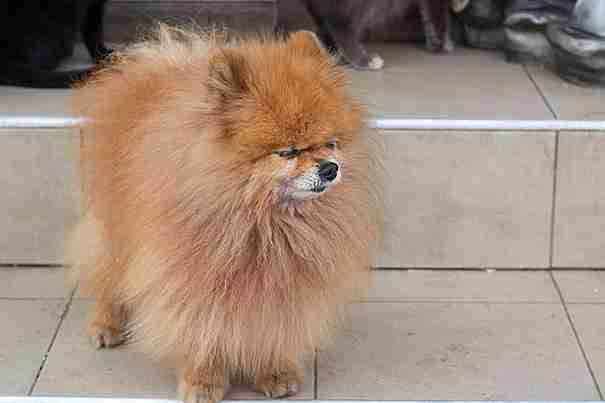

QUESTION : What color is the dog?

RÉPONSE : The dog is brown.

Attention : vérifie la réponse avec l’image.


In [19]:
image_path = input(
    "Chemin de l’image "
    "(Entrée pour /content/chien2.jpg) : "
).strip()

if not image_path:
    image_path = "/content/chien2.jpg"

question = input("Ta question : ").strip()

try:
    assistant_answer = multimodal_assistant(
        image_path,
        question
    )
except (FileNotFoundError, ValueError, OSError) as error:
    print("À corriger :", error)

IMAGE : chien2.jpg


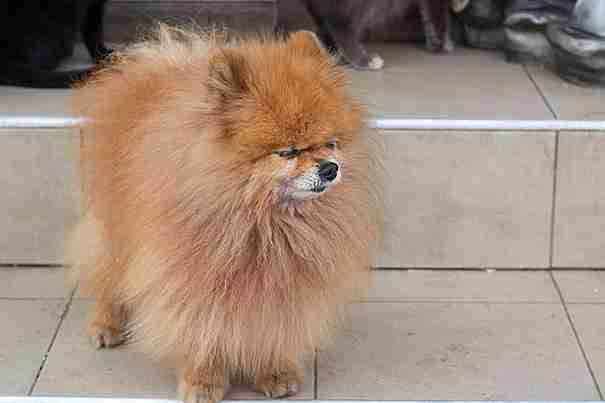

QUESTION : What animal can you see? Describe its colors.

RÉPONSE : In the image, you can see a fluffy, long-haired dog with a mix of brown and white colors.

Attention : vérifie la réponse avec l’image.


In [20]:
image_path = "/content/chien2.jpg"
question = "What animal can you see? Describe its colors."

assistant_answer = multimodal_assistant(
    image_path,
    question
)

IMAGE : football1.jpg


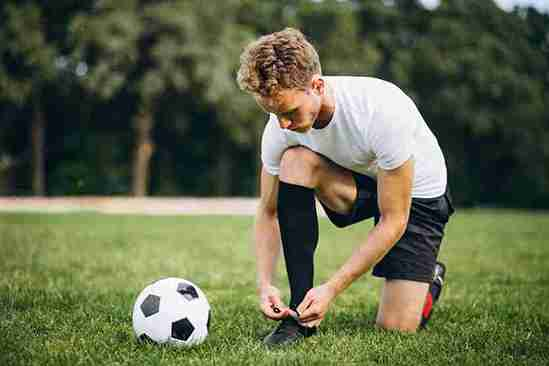

QUESTION : What is the person doing?

RÉPONSE : The person is tying his shoe while kneeling on the grass.

Attention : vérifie la réponse avec l’image.


In [21]:
image_path = "/content/football1.jpg"
question = "What is the person doing?"

assistant_answer = multimodal_assistant(
    image_path,
    question
)

In [22]:
df_assistant_history = pd.DataFrame(assistant_history)
display(df_assistant_history)

,Image,Question,Answer
0,/content/chien2.jpg,What color is the dog?,The dog is brown.
1,/content/chien2.jpg,What animal can you see? Describe its colors.,"In the image, you can see a fluffy, long-haired dog with a mix of brown and white colors."
2,/content/football1.jpg,What is the person doing?,The person is tying his shoe while kneeling on the grass.


Conclusion:

This lab introduced two complementary vision–language models: CLIP and LLaVA. CLIP correctly classified all 10 test images, achieving 100% accuracy on this small dataset. It also supported text-to-image retrieval and demonstrated sensitivity to prompt wording.

LLaVA generated descriptions and answered visual questions. Human evaluation accepted 20 of 25 answers, giving a VQA accuracy of 80%. Errors involved scene interpretation, actions, postures, and nonexistent objects.

The absent-bicycle experiment showed that questions containing false assumptions can lead to invented details. The questions were asked independently, without passing previous answers to the model.

Finally, a small multimodal assistant was implemented and tested on two images. The results demonstrate useful capabilities, but also the need for human verification. The CLIP and VQA accuracies concern different tasks and small test sets, so they do not establish general performance or the overall superiority of either model.